## Offensive Performance Analysis — 2025 vs. 2026

The goal of this analysis is to identify the statistical differences between the Toronto Blue Jays' 2025 and 2026 seasons and determine which factors may have contributed to changes in team performance.

The analysis will focus on four areas: offensive performance, pitching performance, defensive performance, and roster changes.

### Offensive Performance — Did the Blue Jays' Offense Decline?

This section will investigate whether Toronto's offensive production improved or declined between the two seasons, both collectively and individually.

**1. Team-Level Analysis:**
- 1.0 Season Performance Overview
- 1.1 Team Offensive Production Overview
- 1.2 Team Offensive Efficiency Overview
- 1.3 Plate Discipline and Baserunning

**2. Player-Level Analysis:**
- 2.0 Player Performance Overview
- 2.1 Returning Players: Improvements and Slumps
- 2.2 Top Offensive Contributors by Season
- 2.3 Lost and New Offensive Contributors
- 2.4 Individual Player Findings

**Objective:** Determine whether reduced offensive production was associated with declining individual performances, roster changes, or broader team-wide trends.

In [32]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Team-Level Analysis

In [33]:
# Load cleaned team batting data
team_batting = pd.read_csv("../data/processed/team_batting_clean.csv")

# Display the dataset
display(team_batting)

,season,wins,losses,finish,runs_per_game,games,plate_appearances,at_bats,runs,hits,...,home_runs,rbi,stolen_bases,caught_stealing,walks,strikeouts,batting_average,on_base_percentage,slugging_percentage,ops
0,2025,94,68,1,4.93,162,6180,5507,798,1461,...,191,771,77,25,520,1099,0.265,0.333,0.427,0.761
1,2026,79,83,5,4.00,162,6041,5447,648,1347,...,152,616,75,17,459,1149,0.247,0.310,0.381,0.692


### 1.0 Season Performance Overview

Before investigating individual performance metrics, we will compare the Toronto Blue Jays' overall results in 2025 and 2026.

The purpose of this section is to establish the magnitude of the team's decline by comparing:

- Total wins and losses
- Winning percentage
- Final American League East standings position

According to our dataset, Toronto finished first in the AL East in 2025 with a 94–68 record, but fell to fifth in 2026 with a 79–83 record.

This analysis will quantify that change before investigating the offensive, pitching, defensive, and roster-related factors that may help explain it.

In [34]:
# Compare wins and losses between the two seasons
season_results = team_batting[
    ["season", "wins", "losses", "finish"]
].copy()

# Calculate winning percentage
season_results["winning_pct"] = (
    season_results["wins"] /
    (season_results["wins"] + season_results["losses"])
)

display(season_results)

,season,wins,losses,finish,winning_pct
0,2025,94,68,1,0.580247
1,2026,79,83,5,0.487654


In [35]:
# Select the results for each season
season_2025 = season_results[season_results["season"] == 2025].iloc[0]
season_2026 = season_results[season_results["season"] == 2026].iloc[0]

# Calculate changes from 2025 to 2026
wins_change = season_2026["wins"] - season_2025["wins"]
losses_change = season_2026["losses"] - season_2025["losses"]

winning_pct_change = (
    season_2026["winning_pct"] - season_2025["winning_pct"]
) * 100

# Display the results
print("Change in wins:", wins_change)
print("Change in losses:", losses_change)
print(f"Change in winning percentage: {winning_pct_change:.2f} percentage points")

Change in wins: -15.0
Change in losses: 15.0
Change in winning percentage: -9.26 percentage points


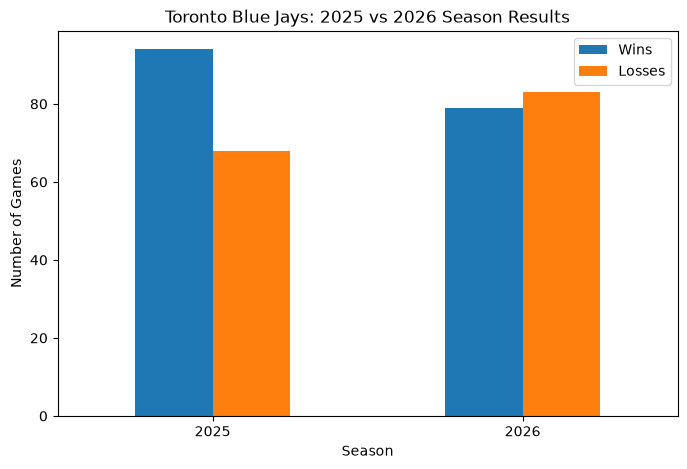

In [36]:
# Create a chart comparing wins and losses
season_results.plot(
    x="season",
    y=["wins", "losses"],
    kind="bar",
    figsize=(8, 5),
    rot=0
)

# Add chart labels
plt.title("Toronto Blue Jays: 2025 vs 2026 Season Results")
plt.xlabel("Season")
plt.ylabel("Number of Games")
plt.legend(["Wins", "Losses"])

# Display the chart
plt.show()

### Findings: Season Performance 

The Toronto Blue Jays experienced a substantial decline in regular-season performance between 2025 and 2026.

In 2025, Toronto recorded 94 wins and 68 losses, finishing first in the American League East. In 2026, the team finished fifth/last place with 79 wins and 83 losses.

This represents a decrease of 15 wins, an increase of 15 losses, and a decline of approximately 9.26 percentage points in winning percentage.

These results establish the magnitude of Toronto's decline but do not explain its causes. The following sections will investigate offensive production, pitching effectiveness, defensive performance, and roster changes to identify potential contributing factors.

### 1.1 Team Offensive Production Overview

This section examines changes in the Toronto Blue Jays' overall offensive production between the 2025 and 2026 seasons.

We will compare five key statistics: total runs, hits, home runs, doubles, and triples.

For each statistic, we will calculate the absolute and percentage changes to identify where offensive production improved or declined. We will also consider games played to ensure a fair comparison between seasons.

In [37]:
# Select team offensive production statistics
offensive_production = team_batting[
    ["season", "games", "runs", "hits", "home_runs", "doubles", "triples"]
].copy()

# Display the selected statistics
display(offensive_production)

,season,games,runs,hits,home_runs,doubles,triples
0,2025,162,798,1461,191,294,13
1,2026,162,648,1347,152,259,8


In [38]:
# Identify each season's offensive statistics
offense_2025 = offensive_production[
    offensive_production["season"] == 2025
].iloc[0]

offense_2026 = offensive_production[
    offensive_production["season"] == 2026
].iloc[0]

# Select the statistics we want to compare
metrics = ["runs", "hits", "home_runs", "doubles", "triples"]

# Calculate absolute and percentage changes
offense_comparison = pd.DataFrame({
    "2025": offense_2025[metrics],
    "2026": offense_2026[metrics]
})

offense_comparison["Change"] = (
    offense_comparison["2026"] - offense_comparison["2025"]
)

offense_comparison["% Change"] = (
    offense_comparison["Change"] / offense_comparison["2025"] * 100
).round(2)

display(offense_comparison)

,2025,2026,Change,% Change
runs,798,648,-150,-18.80
hits,1461,1347,-114,-7.80
home_runs,191,152,-39,-20.42
doubles,294,259,-35,-11.90
triples,13,8,-5,-38.46


### Findings: Offensive Production

The Toronto Blue Jays experienced declines across all five offensive production metrics between 2025 and 2026.

Total runs scored decreased from 798 to 648, representing an 18.80% decline. Meanwhile, hits fell by 7.80%, suggesting that run production deteriorated more sharply than the team's ability to record hits.

Power production also declined considerably. Home runs decreased by 20.42%, doubles by 11.90%, and triples by 38.46%. However, the relatively small number of triples means their percentage change should be interpreted cautiously.

These findings suggest that reduced extra-base-hit production may have contributed to Toronto's offensive struggles in 2026. Further analysis of batting average, on-base percentage, slugging percentage, and OPS will help determine whether the team also became less effective at reaching base and generating power.

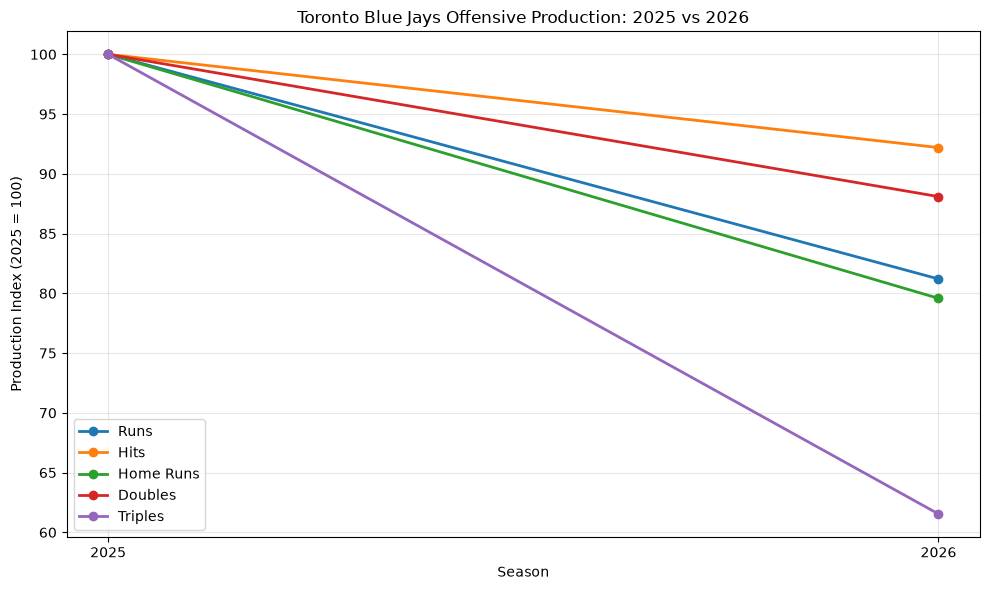

In [39]:
import matplotlib.pyplot as plt

# Select offensive statistics
metrics = ["runs", "hits", "home_runs", "doubles", "triples"]

# Set 2025 as the baseline (100) for each statistic
normalized_offense = (
    offensive_production.set_index("season")[metrics]
    / offensive_production.set_index("season")[metrics].loc[2025]
) * 100

# Create the line chart
plt.figure(figsize=(10, 6))

for metric in metrics:
    plt.plot(
        normalized_offense.index,
        normalized_offense[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("_", " ").title()
    )

plt.title("Toronto Blue Jays Offensive Production: 2025 vs 2026")
plt.xlabel("Season")
plt.ylabel("Production Index (2025 = 100)")
plt.xticks([2025, 2026])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### How to Interpret the Chart

This line chart illustrates the percentage change in the Blue Jays' offensive production between 2025 and 2026. All statistics are normalized to a baseline of **100 in 2025**, allowing metrics with different scales to be compared fairly.

For example, a value of 80 represents a 20% decrease from 2025. Steeper downward lines indicate larger percentage declines.

**Note:** Since only two seasons are being compared, the lines represent changes between seasons rather than continuous trends over time.

### 1.2 Team Offensive Efficiency Overview

While offensive production measures the total number of runs and hits generated, offensive efficiency helps evaluate how effectively a team reaches base and produces extra-base hits.

This section compares batting average (BA), on-base percentage (OBP), slugging percentage (SLG), and on-base plus slugging (OPS) between 2025 and 2026.

The objective is to determine whether declines in on-base ability, hitting power, or both were associated with the team's reduced run production.

In [40]:
# Select offensive efficiency statistics
efficiency_metrics = [
    "batting_average",
    "on_base_percentage",
    "slugging_percentage",
    "ops"
]

# Organize statistics by season
offensive_efficiency = team_batting.set_index("season")[
    efficiency_metrics
]

# Calculate changes from 2025 to 2026
efficiency_comparison = pd.DataFrame({
    "2025": offensive_efficiency.loc[2025],
    "2026": offensive_efficiency.loc[2026]
})

efficiency_comparison["Change"] = (
    efficiency_comparison["2026"] - efficiency_comparison["2025"]
)

efficiency_comparison["% Change"] = (
    efficiency_comparison["Change"] /
    efficiency_comparison["2025"] * 100
).round(2)

display(efficiency_comparison)

,2025,2026,Change,% Change
batting_average,0.265,0.247,-0.018,-6.79
on_base_percentage,0.333,0.310,-0.023,-6.91
slugging_percentage,0.427,0.381,-0.046,-10.77
ops,0.761,0.692,-0.069,-9.07


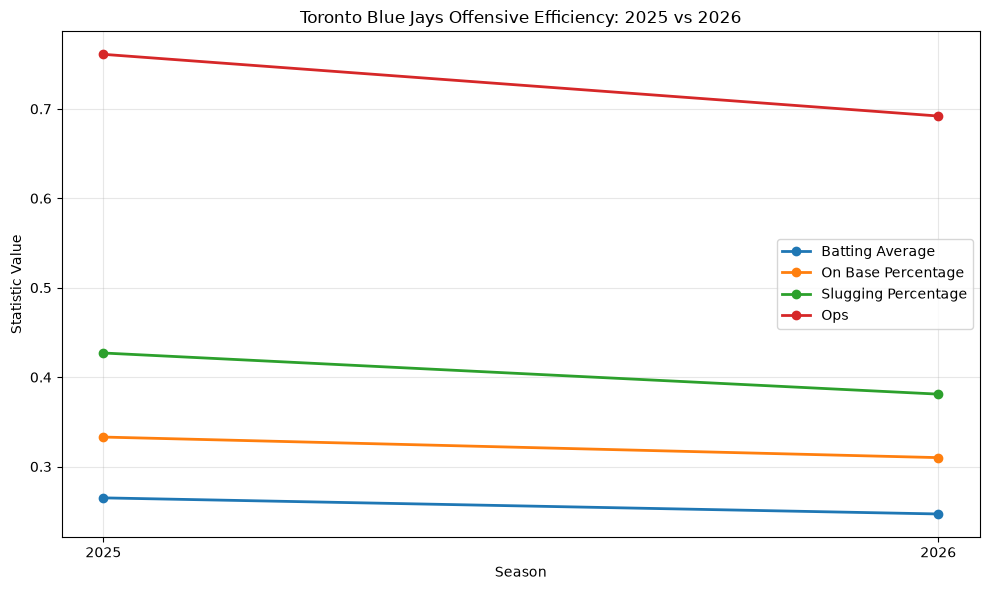

In [41]:
# Visualize changes in team offensive efficiency
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for metric in efficiency_metrics:
    plt.plot(
        offensive_efficiency.index,
        offensive_efficiency[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("_", " ").title()
    )

plt.title("Toronto Blue Jays Offensive Efficiency: 2025 vs 2026")
plt.xlabel("Season")
plt.ylabel("Statistic Value")
plt.xticks([2025, 2026])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

### Findings: Offensive Efficiency

The Toronto Blue Jays experienced declines across all four offensive efficiency metrics between 2025 and 2026.

Slugging percentage recorded the largest relative decrease, falling from .427 to .381 (−10.77%), indicating a reduction in the team's ability to generate total bases per at-bat. This finding is consistent with the decline in home runs and extra-base hits identified in Section 1.1.

On-base percentage decreased from .333 to .310 (−6.91%), while batting average declined from .265 to .247 (−6.79%). These results suggest that Toronto became less effective at both recording hits and reaching base.

Overall OPS fell from .761 to .692 (−9.07%), reflecting declines in both on-base ability and hitting power.

Together, these findings suggest that reduced offensive efficiency, particularly slugging performance, may help explain the team's substantial decrease in runs scored during 2026.

### 1.3 Plate Discipline and Baserunning

This section examines changes in the Toronto Blue Jays' plate discipline and baserunning between the 2025 and 2026 seasons.

We will compare three key statistics:

- **Walks (BB):** Did the team earn more or fewer walks, potentially affecting its ability to reach base?
- **Strikeouts (SO):** Did the team strike out more frequently, potentially limiting opportunities to put the ball in play?
- **Stolen Bases (SB):** Did the team become more or less aggressive and successful on the basepaths?

In addition to comparing raw totals, we will calculate walk and strikeout rates using plate appearances to account for differences in offensive opportunities.

**Objective:** Determine whether changes in plate discipline and baserunning accompanied the team's decline in offensive production.

In [42]:
# Select plate discipline and baserunning statistics
discipline = team_batting[
    ["season", "plate_appearances", "walks", "strikeouts",
     "stolen_bases", "caught_stealing"]
].copy()

display(discipline)

,season,plate_appearances,walks,strikeouts,stolen_bases,caught_stealing
0,2025,6180,520,1099,77,25
1,2026,6041,459,1149,75,17


In [43]:
# Calculate walk rate as a percentage of plate appearances
discipline["BB_rate"] = (
    discipline["walks"] / discipline["plate_appearances"] * 100
)

# Calculate strikeout rate as a percentage of plate appearances
discipline["SO_rate"] = (
    discipline["strikeouts"] / discipline["plate_appearances"] * 100
)

# Calculate stolen-base success rate
discipline["SB_success_rate"] = (
    discipline["stolen_bases"] /
    (discipline["stolen_bases"] + discipline["caught_stealing"]) * 100
)

# Display results rounded to two decimal places
display(discipline.round(2))

,season,plate_appearances,walks,strikeouts,stolen_bases,caught_stealing,BB_rate,SO_rate,SB_success_rate
0,2025,6180,520,1099,77,25,8.41,17.78,75.49
1,2026,6041,459,1149,75,17,7.60,19.02,81.52


In [44]:
# Select metrics for year-over-year comparison
discipline_metrics = [
    "walks",
    "strikeouts",
    "stolen_bases",
    "BB_rate",
    "SO_rate",
    "SB_success_rate"
]

discipline_indexed = discipline.set_index("season")

discipline_comparison = pd.DataFrame({
    "2025": discipline_indexed.loc[2025, discipline_metrics],
    "2026": discipline_indexed.loc[2026, discipline_metrics]
})

# Calculate absolute changes
discipline_comparison["Change"] = (
    discipline_comparison["2026"] - discipline_comparison["2025"]
)

# Calculate relative percentage changes
discipline_comparison["% Change"] = (
    discipline_comparison["Change"] /
    discipline_comparison["2025"] * 100
).round(2)

display(discipline_comparison.round(2))

,2025,2026,Change,% Change
walks,520.00,459.00,-61.00,-11.73
strikeouts,1099.00,1149.00,50.00,4.55
stolen_bases,77.00,75.00,-2.00,-2.60
BB_rate,8.41,7.60,-0.82,-9.70
SO_rate,17.78,19.02,1.24,6.96
SB_success_rate,75.49,81.52,6.03,7.99


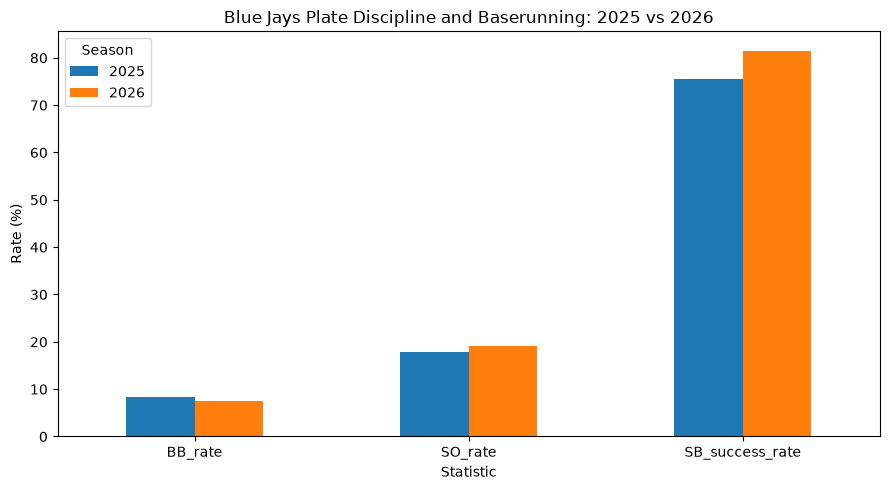

In [45]:
# Compare plate discipline and baserunning rates
import matplotlib.pyplot as plt

rate_metrics = ["BB_rate", "SO_rate", "SB_success_rate"]

discipline_rates = discipline.set_index("season")[rate_metrics].T

discipline_rates.columns = ["2025", "2026"]

discipline_rates.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Blue Jays Plate Discipline and Baserunning: 2025 vs 2026")
plt.xlabel("Statistic")
plt.ylabel("Rate (%)")
plt.legend(title="Season")
plt.tight_layout()
plt.show()

### 1.3 Findings: Plate Discipline and Baserunning

The Toronto Blue Jays experienced a decline in plate discipline between the 2025 and 2026 seasons.

Total walks decreased from 520 to 459 (−11.73%), while the walk rate declined from 8.41% to 7.60%. Meanwhile, strikeouts increased from 1,099 to 1,149 (+4.55%), with the strikeout rate rising from 17.78% to 19.02%.

These findings indicate that Toronto earned walks less frequently and struck out more often in 2026. This deterioration in plate discipline may have contributed to the declines in on-base percentage and overall offensive production identified in earlier sections.

Baserunning presented a different trend. Although stolen bases declined slightly from 77 to 75, stolen-base success improved from 75.49% to 81.52%, indicating greater efficiency on attempted steals.

Overall, the results suggest that reduced plate discipline was another potential contributor to Toronto's offensive struggles, while stolen-base efficiency was an area of improvement.

## 2. Individual Player Offensive Analysis

### 2.0 Player Performance Overview

Following the team-level offensive analysis, this section examines individual player batting performance during the 2025 and 2026 seasons.

The objective is to identify which players contributed most to Toronto's offensive production, which returning players improved or declined, and whether changes in personnel or playing time were associated with the team's reduced offensive output.

**Key Areas of Investigation:**

- **Individual Offensive Efficiency:** Compare batting average (BA), on-base percentage (OBP), slugging percentage (SLG), and OPS.
- **Offensive Production:** Examine runs, hits, home runs, RBIs, and total bases.
- **Player Improvements and Slumps:** Identify returning hitters who experienced significant changes in performance.
- **Playing Time:** Consider games played and plate appearances when evaluating individual statistics.
- **Roster Changes:** Investigate whether the absence of key 2025 contributors or the arrival of new players affected offensive production.

We will distinguish between returning players and players appearing in only one of the two seasons to ensure meaningful comparisons.

In [46]:
# Load cleaned player batting datasets
player_batting_2025 = pd.read_csv(
    "../data/processed/player_batting_2025_clean.csv"
)

player_batting_2026 = pd.read_csv(
    "../data/processed/player_batting_2026_clean.csv"
)

# Display the first five players from each season
print("2025 Player Batting:")
display(player_batting_2025.head())

print("2026 Player Batting:")
display(player_batting_2026.head())

2025 Player Batting:


,Player,Pos,WAR,G,PA,AB,R,H,2B,3B,...,OPS,OPS+,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB
0,Alejandro Kirk,C,2.3,130,506,451,45,127,18,0,...,0.769,111.0,0.334,109.0,190,16,1,0,6,2
1,Vladimir Guerrero Jr.,1B,4.6,156,680,589,96,172,34,0,...,0.848,132.0,0.365,132.0,275,17,6,0,4,8
2,Andrés Giménez,2B,1.1,101,369,329,39,69,11,1,...,0.598,65.0,0.277,64.0,103,8,11,1,3,0
3,Bo Bichette,SS,3.4,139,628,582,78,181,44,1,...,0.840,128.0,0.364,132.0,281,17,3,0,3,2
4,Addison Barger,3B,1.2,135,502,460,61,112,32,1,...,0.756,104.0,0.320,99.0,209,8,3,0,2,4


2026 Player Batting:


,Player,Pos,WAR,G,PA,AB,R,H,2B,3B,...,OPS,OPS+,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB
0,Brandon Valenzuela,C,1.6,91,271,239,29,54,9,0,...,0.688,89,0.311,88,90,4,1,1,1,0
1,Vladimir Guerrero Jr.,1B,1.1,144,609,542,72,141,25,0,...,0.688,90,0.309,88,193,20,5,0,6,5
2,Ernie Clement,2B,1.1,158,621,590,60,153,33,1,...,0.649,78,0.294,75,215,15,2,0,7,0
3,Andrés Giménez,SS,1.1,148,508,468,38,114,25,1,...,0.649,78,0.290,70,168,7,16,2,5,2
4,Kazuma Okamoto,3B,2.5,156,636,568,81,132,26,0,...,0.762,107,0.335,106,257,15,6,0,3,0


### 2.1 Returning Players: Improvements and Slumps

This section compares the offensive performance of Toronto Blue Jays players who recorded batting statistics in both the 2025 and 2026 seasons.

By matching returning players across both datasets, we can investigate changes in batting average (BA), on-base percentage (OBP), slugging percentage (SLG), and OPS.

We will also consider plate appearances (PA) to distinguish meaningful performance changes from fluctuations caused by limited playing time.

**Objective:** Identify which returning players experienced offensive improvements or declines and assess how those changes may have contributed to the team's overall offensive performance.

In [47]:
# Match players who appeared in both seasons
returning_hitters = pd.merge(
    player_batting_2025,
    player_batting_2026,
    on="Player",
    how="inner",
    suffixes=("_2025", "_2026")
)

# Display the number of returning players
print("Returning hitters:", len(returning_hitters))

# Preview the merged dataset
display(returning_hitters.head())

Returning hitters: 12


,Player,Pos_2025,WAR_2025,G_2025,PA_2025,AB_2025,R_2025,H_2025,2B_2025,3B_2025,...,OPS_2026,OPS+_2026,rOBA_2026,Rbat+_2026,TB_2026,GIDP_2026,HBP_2026,SH_2026,SF_2026,IBB_2026
0,Alejandro Kirk,C,2.3,130,506,451,45,127,18,0,...,0.767,111,0.337,107,115,11,0,0,3,5
1,Vladimir Guerrero Jr.,1B,4.6,156,680,589,96,172,34,0,...,0.688,90,0.309,88,193,20,5,0,6,5
2,Andrés Giménez,2B,1.1,101,369,329,39,69,11,1,...,0.649,78,0.290,70,168,7,16,2,5,2
3,Addison Barger,3B,1.2,135,502,460,61,112,32,1,...,0.305,-11,0.170,-11,2,1,0,0,1,0
4,Davis Schneider,LF,1.3,82,227,188,33,44,5,0,...,0.624,73,0.298,78,39,1,1,1,1,0


In [48]:
# Calculate changes in batting statistics for returning hitters
returning_hitters["BA_change"] = (
    returning_hitters["BA_2026"] - returning_hitters["BA_2025"]
)

returning_hitters["OBP_change"] = (
    returning_hitters["OBP_2026"] - returning_hitters["OBP_2025"]
)

returning_hitters["SLG_change"] = (
    returning_hitters["SLG_2026"] - returning_hitters["SLG_2025"]
)

returning_hitters["OPS_change"] = (
    returning_hitters["OPS_2026"] - returning_hitters["OPS_2025"]
)

In [49]:
# Compare OPS changes among returning hitters
ops_comparison = returning_hitters[
    ["Player", "PA_2025", "PA_2026",
     "OPS_2025", "OPS_2026", "OPS_change"]
].copy()

# Sort from the largest improvement to the largest decline
ops_comparison = ops_comparison.sort_values(
    by="OPS_change",
    ascending=False
)

display(ops_comparison)

,Player,PA_2025,PA_2026,OPS_2025,OPS_2026,OPS_change
11,Jonatan Clase,112,25,0.588,0.905,0.317
2,Andrés Giménez,369,508,0.598,0.649,0.051
0,Alejandro Kirk,506,313,0.769,0.767,-0.002
6,Nathan Lukes,438,450,0.730,0.715,-0.015
9,Myles Straw,299,330,0.680,0.646,-0.034
8,Ernie Clement,588,621,0.711,0.649,-0.062
5,Daulton Varsho,271,365,0.833,0.682,-0.151
1,Vladimir Guerrero Jr.,680,609,0.848,0.688,-0.160
4,Davis Schneider,227,156,0.797,0.624,-0.173
7,George Springer,586,517,0.959,0.726,-0.233


**Sample Selection:** To compare returning hitters, players must have recorded at least 150 plate appearances in both 2025 and 2026. This threshold was selected to include both everyday starters and contributing role players while excluding extremely limited batting samples. Results for players with fewer plate appearances should still be interpreted cautiously.

In [50]:
# Focus on returning hitters with substantial playing time
regular_hitters = returning_hitters[
    (returning_hitters["PA_2025"] >= 150) &
    (returning_hitters["PA_2026"] >= 150)
].copy()

# Select relevant statistics
regular_ops = regular_hitters[
    ["Player", "PA_2025", "PA_2026",
     "OPS_2025", "OPS_2026", "OPS_change"]
]

# Sort players from largest OPS decline to largest improvement
regular_ops = regular_ops.sort_values("OPS_change")

display(regular_ops)

,Player,PA_2025,PA_2026,OPS_2025,OPS_2026,OPS_change
7,George Springer,586,517,0.959,0.726,-0.233
4,Davis Schneider,227,156,0.797,0.624,-0.173
1,Vladimir Guerrero Jr.,680,609,0.848,0.688,-0.160
5,Daulton Varsho,271,365,0.833,0.682,-0.151
8,Ernie Clement,588,621,0.711,0.649,-0.062
9,Myles Straw,299,330,0.680,0.646,-0.034
6,Nathan Lukes,438,450,0.730,0.715,-0.015
0,Alejandro Kirk,506,313,0.769,0.767,-0.002
2,Andrés Giménez,369,508,0.598,0.649,0.051


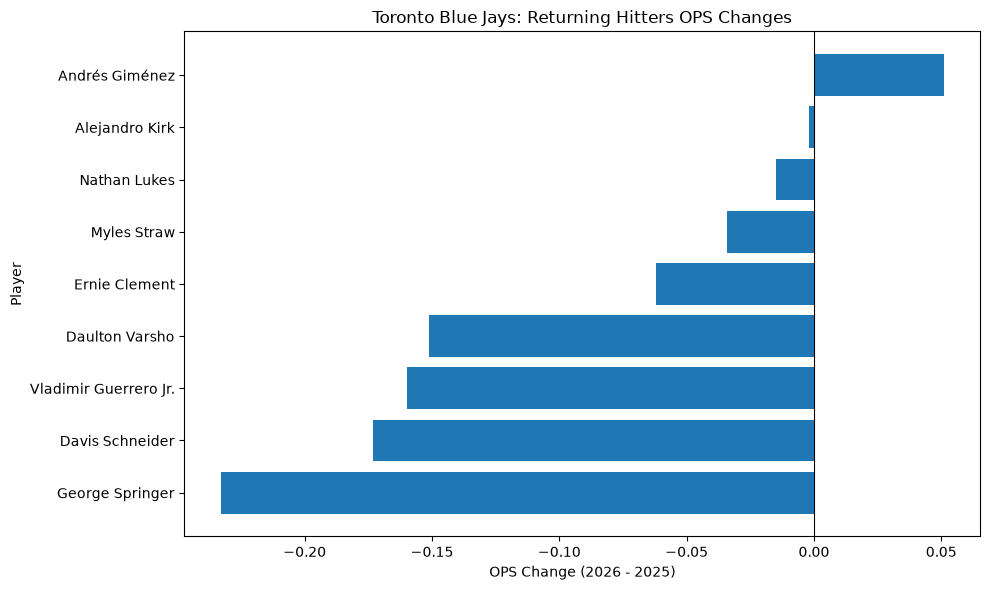

In [51]:
# Visualize OPS changes among returning hitters
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    regular_ops["Player"],
    regular_ops["OPS_change"]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Toronto Blue Jays: Returning Hitters OPS Changes")
plt.xlabel("OPS Change (2026 - 2025)")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

### 2.1 Findings: Returning Hitters

Among the nine returning hitters who recorded at least 150 plate appearances in both seasons, eight experienced a decline in OPS during 2026.

George Springer recorded the largest decline, falling from .959 to .726 (−.233), followed by Davis Schneider (−.173), Vladimir Guerrero Jr. (−.160), and Daulton Varsho (−.151).

Andrés Giménez was the only player in this group to improve, increasing his OPS from .598 to .649 (+.051). Alejandro Kirk remained relatively consistent, with an OPS change of only −.002.

The widespread decline among returning players suggests that Toronto's reduced offensive efficiency was not isolated to a single hitter. However, OPS changes alone do not establish each player's contribution to the team's decrease in total runs.

Further investigation of batting average, on-base percentage, slugging percentage, and playing time will help identify the nature and potential impact of these individual declines.

### 2.2 Top Offensive Contributors by Season

This section identifies the Toronto Blue Jays' leading offensive contributors during the 2025 and 2026 seasons.

We will compare individual player production using five statistics:

- **Runs (R):** The number of runs scored by each player.
- **Hits (H):** The number of successful hits recorded.
- **Home Runs (HR):** A measure of individual home-run power.
- **Runs Batted In (RBI):** The number of runs credited to a hitter through their batting performance.
- **Total Bases (TB):** A measure of bases accumulated through hits, accounting for extra-base hits.

We will also examine plate appearances (PA) to distinguish total contributions from differences in playing time.

**Objective:** Identify each season's most productive hitters and investigate whether Toronto experienced a decline in offensive contributions from its leading players.

In [52]:
# Find the top 5 players in runs scored for each season

top_runs_2025 = player_batting_2025.nlargest(5, "R")[
    ["Player", "PA", "R", "H", "HR", "RBI", "TB"]
]

top_runs_2026 = player_batting_2026.nlargest(5, "R")[
    ["Player", "PA", "R", "H", "HR", "RBI", "TB"]
]

print("Top 5 Run Scorers — 2025")
display(top_runs_2025)

print("Top 5 Run Scorers — 2026")
display(top_runs_2026)

Top 5 Run Scorers — 2025


,Player,PA,R,H,HR,RBI,TB
8,George Springer,586,106,154,32,84,279
1,Vladimir Guerrero Jr.,680,96,172,23,84,275
9,Ernie Clement,588,83,151,9,50,217
3,Bo Bichette,628,78,181,18,94,281
4,Addison Barger,502,61,112,21,74,209


Top 5 Run Scorers — 2026


,Player,PA,R,H,HR,RBI,TB
4,Kazuma Okamoto,636,81,132,33,92,257
1,Vladimir Guerrero Jr.,609,72,141,9,57,193
2,Ernie Clement,621,60,153,9,48,215
8,George Springer,517,59,115,15,54,187
7,Nathan Lukes,450,48,113,10,41,158


In [53]:
# Identify the top 5 home run hitters in each season

top_hr_2025 = player_batting_2025.nlargest(5, "HR")[
    ["Player", "PA", "HR", "RBI", "SLG", "OPS"]
]

top_hr_2026 = player_batting_2026.nlargest(5, "HR")[
    ["Player", "PA", "HR", "RBI", "SLG", "OPS"]
]

print("Top 5 Home Run Hitters — 2025")
display(top_hr_2025)

print("Top 5 Home Run Hitters — 2026")
display(top_hr_2026)

Top 5 Home Run Hitters — 2025


,Player,PA,HR,RBI,SLG,OPS
8,George Springer,586,32,84,0.560,0.959
1,Vladimir Guerrero Jr.,680,23,84,0.467,0.848
4,Addison Barger,502,21,74,0.454,0.756
6,Daulton Varsho,271,20,55,0.548,0.833
3,Bo Bichette,628,18,94,0.483,0.840


Top 5 Home Run Hitters — 2026


,Player,PA,HR,RBI,SLG,OPS
4,Kazuma Okamoto,636,33,92,0.452,0.762
8,George Springer,517,15,54,0.405,0.726
7,Nathan Lukes,450,10,41,0.387,0.715
9,Alejandro Kirk,313,10,43,0.415,0.767
0,Brandon Valenzuela,271,9,24,0.377,0.688


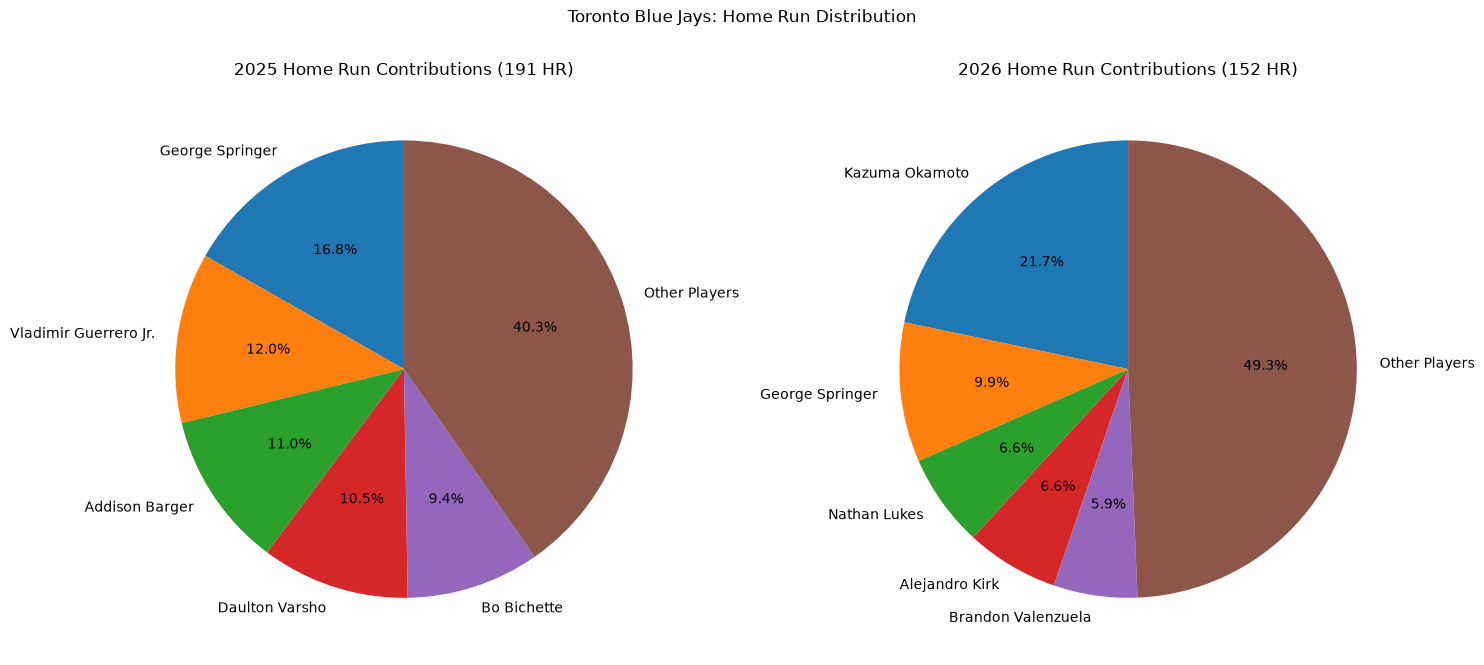

In [54]:
# Calculate home runs by players outside the top five
other_hr_2025 = 191 - top_hr_2025["HR"].sum()
other_hr_2026 = 152 - top_hr_2026["HR"].sum()

# Prepare labels and values
labels_2025 = top_hr_2025["Player"].tolist() + ["Other Players"]
values_2025 = top_hr_2025["HR"].tolist() + [other_hr_2025]

labels_2026 = top_hr_2026["Player"].tolist() + ["Other Players"]
values_2026 = top_hr_2026["HR"].tolist() + [other_hr_2026]

# Create the pie charts
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].pie(
    values_2025,
    labels=labels_2025,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("2025 Home Run Contributions (191 HR)")

axes[1].pie(
    values_2026,
    labels=labels_2026,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("2026 Home Run Contributions (152 HR)")

plt.suptitle("Toronto Blue Jays: Home Run Distribution")
plt.tight_layout()
plt.show()

### Home Run Distribution: 2025 vs. 2026

These pie charts illustrate the proportion of Toronto's total home runs contributed by the five leading home run hitters in each season.

Each slice represents a player's share of the team's home runs, while "Other Players" combines the remaining contributors.

Although Toronto's total home runs declined from 191 in 2025 to 152 in 2026, the charts focus on how home run production was distributed among players rather than the size of the overall decline.

These visualizations help identify the team's primary power hitters and whether home run production became more concentrated among fewer players.

In [55]:
# Identify the top 5 players in hits, RBIs, and total bases

for stat in ["H", "RBI", "TB"]:

    print(f"\nTop 5 in {stat} — 2025")
    display(
        player_batting_2025.nlargest(5, stat)[
            ["Player", "PA", stat]
        ]
    )

    print(f"Top 5 in {stat} — 2026")
    display(
        player_batting_2026.nlargest(5, stat)[
            ["Player", "PA", stat]
        ]
    )


Top 5 in H — 2025


,Player,PA,H
3,Bo Bichette,628,181
1,Vladimir Guerrero Jr.,680,172
8,George Springer,586,154
9,Ernie Clement,588,151
0,Alejandro Kirk,506,127


Top 5 in H — 2026


,Player,PA,H
2,Ernie Clement,621,153
1,Vladimir Guerrero Jr.,609,141
4,Kazuma Okamoto,636,132
8,George Springer,517,115
3,Andrés Giménez,508,114



Top 5 in RBI — 2025


...

,Player,PA,RBI
4,Kazuma Okamoto,636,92
3,Andrés Giménez,508,59
1,Vladimir Guerrero Jr.,609,57
8,George Springer,517,54
2,Ernie Clement,621,48



Top 5 in TB — 2025


,Player,PA,TB
3,Bo Bichette,628,281
8,George Springer,586,279
1,Vladimir Guerrero Jr.,680,275
9,Ernie Clement,588,217
4,Addison Barger,502,209


Top 5 in TB — 2026


,Player,PA,TB
4,Kazuma Okamoto,636,257
2,Ernie Clement,621,215
1,Vladimir Guerrero Jr.,609,193
8,George Springer,517,187
3,Andrés Giménez,508,168


### 2.2 Findings: Top Offensive Contributors

The comparison of Toronto's leading offensive contributors reveals substantial differences between the 2025 and 2026 seasons.

**Loss of Key Contributors**

Bo Bichette was Toronto's leading hitter in several major production categories in 2025, recording 181 hits, 94 RBIs, and 281 total bases. His absence from the 2026 batting dataset represents the loss of a significant source of offensive production.

**Declining Production from Returning Players**

George Springer and Vladimir Guerrero Jr. experienced substantial declines in hits, RBIs, and total bases. Springer recorded 92 fewer total bases, while Guerrero Jr. recorded 82 fewer. These results align with the OPS declines identified in Section 2.1, although reduced plate appearances also contributed to lower counting-stat totals.

**Consistent Contributors**

Ernie Clement maintained relatively stable hit production, recording 151 hits in 2025 and 153 in 2026. His total bases also remained similar, demonstrating that not every returning player experienced a substantial decline in total production.

**Emergence of New Contributors**

Kazuma Okamoto became one of Toronto's leading offensive contributors in 2026, recording 33 home runs, 92 RBIs, and 257 total bases. However, his production coincided with an overall decline in the team's offensive statistics.

**Overall Finding**

Toronto's offensive decline was associated with reduced production from several established hitters, the absence of important 2025 contributors, and changes in the composition of the lineup.

Further analysis is necessary to distinguish the effects of roster turnover, reduced playing time, and individual performance declines.


### 2.3 Lost and New Offensive Contributors

This section investigates how changes in Toronto's player personnel affected offensive production between the 2025 and 2026 seasons.

Using the individual batting datasets, we will identify three categories of players:

- **Returning Hitters:** Players who recorded batting statistics in both seasons.
- **Departing Hitters:** Players who appeared in the 2025 batting dataset but not in 2026.
- **New Hitters:** Players who appeared in the 2026 batting dataset but not in 2025.

We will then compare the offensive production associated with departing and new hitters, focusing on runs, hits, home runs, RBIs, and total bases.

**Objective:** Determine whether production from new hitters compensated for the contributions of players who no longer appeared in Toronto's batting data.

*Note: These categories describe appearances in the batting datasets. They do not necessarily establish whether a player was traded, released, injured, or otherwise unavailable.*

In [56]:
# Identify returning, departing, and new hitters
player_comparison = pd.merge(
    player_batting_2025,
    player_batting_2026,
    on="Player",
    how="outer",
    suffixes=("_2025", "_2026"),
    indicator=True
)

# Count players in each category
print(player_comparison["_merge"].value_counts())

_merge
left_only     15
right_only    13
both          12
Name: count, dtype: int64


In [57]:
# Players appearing only in the 2025 batting dataset
departing_hitters = player_comparison[
    player_comparison["_merge"] == "left_only"
][
    ["Player", "PA_2025", "R_2025",
     "H_2025", "HR_2025", "RBI_2025", "TB_2025"]
].copy()

# Players appearing only in the 2026 batting dataset
new_hitters = player_comparison[
    player_comparison["_merge"] == "right_only"
][
    ["Player", "PA_2026", "R_2026",
     "H_2026", "HR_2026", "RBI_2026", "TB_2026"]
].copy()

# Sort both groups by total bases
departing_hitters = departing_hitters.sort_values(
    "TB_2025", ascending=False
)

new_hitters = new_hitters.sort_values(
    "TB_2026", ascending=False
)

print("2025-Only Hitters:")
display(departing_hitters)

print("2026-Only Hitters:")
display(new_hitters)

2025-Only Hitters:


,Player,PA_2025,R_2025,H_2025,HR_2025,RBI_2025,TB_2025
6,Bo Bichette,628.0,78.0,181.0,18.0,94.0,281.0
5,Anthony Santander,221.0,16.0,34.0,6.0,18.0,57.0
20,Joey Loperfido,104.0,12.0,32.0,4.0,14.0,48.0
33,Ty France,103.0,9.0,26.0,1.0,8.0,35.0
37,Will Wagner,132.0,13.0,27.0,0.0,7.0,34.0
1,Alan Roden,113.0,12.0,20.0,1.0,8.0,30.0
17,Isiah Kiner-Falefa,31.0,5.0,7.0,1.0,5.0,11.0
3,Ali Sánchez,21.0,2.0,5.0,0.0,0.0,7.0
25,Leo Jiménez,32.0,2.0,2.0,1.0,1.0,5.0
27,Michael Stefanic,25.0,1.0,4.0,0.0,0.0,4.0


2026-Only Hitters:


,Player,PA_2026,R_2026,H_2026,HR_2026,RBI_2026,TB_2026
23,Kazuma Okamoto,636.0,81.0,132.0,33.0,92.0,257.0
19,Jesús Sánchez,299.0,24.0,70.0,8.0,35.0,112.0
7,Brandon Valenzuela,271.0,29.0,54.0,9.0,24.0,90.0
8,Brett Bateman,181.0,28.0,52.0,2.0,11.0,67.0
39,Yohendrick Piñango,180.0,12.0,44.0,5.0,20.0,67.0
10,Charles McAdoo,106.0,12.0,25.0,3.0,14.0,38.0
22,Josh Smith,89.0,15.0,14.0,5.0,7.0,31.0
26,Luis Urías,59.0,5.0,13.0,3.0,8.0,25.0
24,Lenyn Sosa,84.0,9.0,15.0,1.0,6.0,22.0
32,Sean Keys,67.0,9.0,12.0,2.0,9.0,20.0


In [58]:
# Calculate total offensive production from 2025-only hitters
departing_totals = departing_hitters[
    ["R_2025", "H_2025", "HR_2025", "RBI_2025", "TB_2025"]
].sum()

# Calculate total offensive production from 2026-only hitters
new_totals = new_hitters[
    ["R_2026", "H_2026", "HR_2026", "RBI_2026", "TB_2026"]
].sum()

# Create a comparison table
turnover_comparison = pd.DataFrame({
    "2025-Only Hitters": departing_totals.values,
    "2026-Only Hitters": new_totals.values
}, index=["Runs", "Hits", "Home Runs", "RBIs", "Total Bases"])

# Calculate differences
turnover_comparison["Difference"] = (
    turnover_comparison["2026-Only Hitters"] -
    turnover_comparison["2025-Only Hitters"]
)

display(turnover_comparison)

,2025-Only Hitters,2026-Only Hitters,Difference
Runs,151.0,229.0,78.0
Hits,340.0,445.0,105.0
Home Runs,32.0,72.0,40.0
RBIs,156.0,232.0,76.0
Total Bases,515.0,747.0,232.0


The Blue Jays' 2026-only hitters produced more offense than their 2025-only hitters across all five categories.

In [59]:
# Compare total production from returning hitters
stats = ["R", "H", "HR", "RBI", "TB"]

returning_comparison = pd.DataFrame({
    "2025": [returning_hitters[f"{stat}_2025"].sum() for stat in stats],
    "2026": [returning_hitters[f"{stat}_2026"].sum() for stat in stats]
}, index=["Runs", "Hits", "Home Runs", "RBIs", "Total Bases"])

# Calculate changes
returning_comparison["Difference"] = (
    returning_comparison["2026"] - returning_comparison["2025"]
)

display(returning_comparison)

,2025,2026,Difference
Runs,647,419,-228
Hits,1121,902,-219
Home Runs,159,80,-79
RBIs,615,384,-231
Total Bases,1839,1331,-508


Results show that the returning hitters experienced substantial declines, while the 2026-only hitters added more production than the 2025-only group contributed.

In [60]:
# Compare plate appearances for returning hitters
pa_2025 = returning_hitters["PA_2025"].sum()
pa_2026 = returning_hitters["PA_2026"].sum()

print("2025 returning hitters PA:", pa_2025)
print("2026 returning hitters PA:", pa_2026)
print("Change in PA:", pa_2026 - pa_2025)

2025 returning hitters PA: 4752
2026 returning hitters PA: 4009
Change in PA: -743


In [61]:
# Calculate production per 100 plate appearances
production_rates = pd.DataFrame({
    "2025": [
        647 / 4752 * 100,
        1121 / 4752 * 100,
        159 / 4752 * 100
    ],
    "2026": [
        419 / 4009 * 100,
        902 / 4009 * 100,
        80 / 4009 * 100
    ]
}, index=["Runs per 100 PA", "Hits per 100 PA", "HR per 100 PA"])

# Calculate percentage changes
production_rates["% Change"] = (
    (production_rates["2026"] - production_rates["2025"])
    / production_rates["2025"] * 100
)

display(production_rates.round(2))

,2025,2026,% Change
Runs per 100 PA,13.62,10.45,-23.24
Hits per 100 PA,23.59,22.50,-4.62
HR per 100 PA,3.35,2.00,-40.36


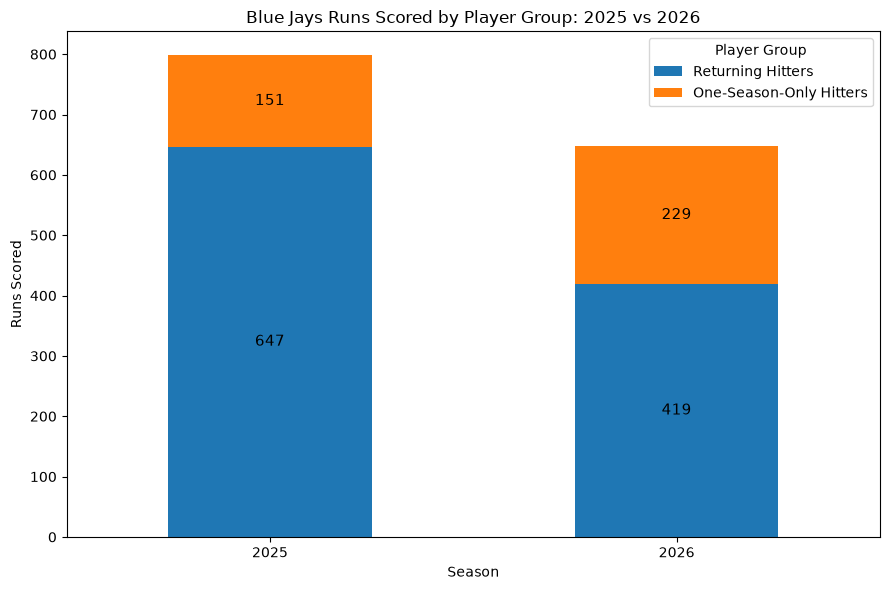

In [62]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a table of runs scored by player group
runs_by_group = pd.DataFrame({
    "Returning Hitters": [647, 419],
    "One-Season-Only Hitters": [151, 229]
}, index=["2025", "2026"])

# Create stacked bar chart
ax = runs_by_group.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    rot=0
)

# Add chart labels
plt.title("Blue Jays Runs Scored by Player Group: 2025 vs 2026")
plt.xlabel("Season")
plt.ylabel("Runs Scored")
plt.legend(title="Player Group")

# Display values inside each bar segment
for container in ax.containers:
    ax.bar_label(container, label_type="center", fontsize=11)

plt.tight_layout()
plt.show()

### Interpreting Offensive Contributions by Player Group

The stacked bar chart compares runs scored by returning hitters and players appearing in only one season.

Returning hitters contributed 647 runs in 2025 but only 419 in 2026, while the one-season-only groups contributed 151 and 229 runs, respectively.

Although the 2026-only hitters produced more runs than the 2025-only group, this increase was not sufficient to offset the substantial decline among returning hitters.

The resulting net decrease of 150 runs matches the team's overall offensive decline, demonstrating how changes in player participation and production contributed to the season-level results.

These comparisons describe the distribution of offensive production but do not independently establish the causes of player performance changes.

### 2.3 Findings: Roster Turnover and Returning Player Production

The comparison of returning, departing, and newly appearing hitters reveals that reduced production among returning players was a major component of Toronto's offensive decline.

The 12 returning hitters collectively recorded 228 fewer runs, 219 fewer hits, and 79 fewer home runs in 2026. Meanwhile, players appearing only in the 2026 batting dataset contributed 78 more runs, 105 more hits, and 40 more home runs than the 2025-only group.

Together, these changes reconcile with Toronto's overall declines of 150 runs, 114 hits, and 39 home runs.

**Playing Time and Efficiency**

Returning hitters recorded 743 fewer plate appearances in 2026, a 15.6% reduction. However, their offensive production declined more sharply than their opportunities.

Home runs per 100 plate appearances decreased by approximately 40.4%, while runs per 100 plate appearances declined by approximately 23.2%.

These results suggest that reduced playing time alone cannot explain the decline in returning-player production. Lower offensive productivity per opportunity was also an important factor.

**Overall Finding**

Although the 2026-only hitters collectively supplied more production than the 2025-only group, this increase did not offset the substantial reduction in production among returning hitters.

The evidence suggests that declining offensive efficiency among established players, combined with changes in playing time and roster composition, was closely associated with Toronto's overall offensive struggles.

## 2.4 Final Individual Player Findings

The individual player analysis reveals that Toronto's offensive decline between 2025 and 2026 was associated with reduced production among returning hitters, changes in playing time, and roster turnover.

#### 1. Declining Performance Among Returning Hitters

Of the nine returning hitters who recorded at least 150 plate appearances in both seasons, eight experienced a decline in OPS.

Several important contributors experienced substantial decreases:

| Player | 2025 OPS | 2026 OPS | Change |
|---|---:|---:|---:|
| George Springer | .959 | .726 | −.233 |
| Davis Schneider | .797 | .624 | −.173 |
| Vladimir Guerrero Jr. | .848 | .688 | −.160 |
| Daulton Varsho | .833 | .682 | −.151 |

George Springer and Vladimir Guerrero Jr. were particularly noteworthy because they experienced substantial declines while maintaining significant playing time.

Andrés Giménez was the only hitter in the qualifying group to improve his OPS, increasing from .598 to .649.

These results suggest that Toronto's offensive struggles were widespread among returning hitters rather than being isolated to one player.

#### 2. Reduced Playing Time and Offensive Productivity

The 12 returning hitters collectively recorded 4,752 plate appearances in 2025 compared with 4,009 in 2026, representing a decline of 743 plate appearances (15.6%).

Their combined production declined considerably:

- Runs scored decreased by 228.
- Hits decreased by 219.
- Home runs decreased by 79.
- Total bases decreased by 508.

Importantly, these declines were not explained by reduced playing time alone.

Home runs per 100 plate appearances decreased by approximately 40.4%, while runs scored per 100 plate appearances declined by approximately 23.2%.

This indicates that returning hitters experienced reduced production per opportunity in addition to receiving fewer opportunities overall.

#### 3. The Absence of Key 2025 Contributors

Bo Bichette was one of Toronto's leading offensive contributors in 2025, recording 181 hits, 94 RBIs, and 281 total bases.

His absence from the 2026 batting dataset represented a significant change in the composition of Toronto's offense.

Other players who appeared in 2025 but not 2026 also contributed to the difference in personnel between the two seasons.

However, absence from the batting dataset alone does not establish the reason a player was unavailable.

#### 4. Contributions from New Hitters

Kazuma Okamoto emerged as Toronto's leading power hitter in 2026, recording 33 home runs, 92 RBIs, and 257 total bases.

The 13 hitters appearing only in the 2026 batting dataset collectively contributed more runs, hits, home runs, RBIs, and total bases than the 15 hitters appearing only in the 2025 dataset.

Despite these additional contributions, Toronto's overall offensive production declined.

This suggests that production from new contributors was insufficient to compensate for reduced production among returning players.

#### 5. Explaining the Overall Offensive Decline

By combining returning-player production with the contributions of players appearing in only one season, we can account for Toronto's overall changes in runs, hits, and home runs.

| Player Group | Change in Runs | Change in Hits | Change in HR |
|---|---:|---:|---:|
| Returning hitters | −228 | −219 | −79 |
| One-season-only groups | +78 | +105 | +40 |
| **Net team change** | **−150** | **−114** | **−39** |

The results demonstrate that the decline in production among returning hitters was larger than the additional production supplied by players appearing only in 2026.

### Overall Conclusion

The evidence suggests that **reduced offensive productivity among returning hitters was a major component of the Toronto Blue Jays' decline in 2026**.

Although roster turnover changed the composition of the lineup, new contributors provided substantial production. The more significant aggregate difference was the sharp reduction in output from players who appeared in both seasons (most importantly George Springer and Vladdy Jr).

These findings are consistent with the team-level declines in runs scored, home runs, batting average, OBP, SLG, and OPS.

However, this analysis describes statistical changes rather than establishing their underlying causes. Further investigation of player availability, pitching, fielding, and roster decisions will provide additional context for Toronto's overall performance decline.